# Production ML and Agentic Analytics: Hands-on Labs

> **Who is this for:** learners who can train a model in a notebook and now want to see what happens *around* the model in production, and how an "AI data analyst" agent is built and tested.
>
> **What you will learn (five labs):**
> - **Lab A, anatomy of a production ML system:** data sources, validation, feature pipeline, feature store, training, model registry, serving, monitoring and the retraining loop, run end to end on a tiny scikit-learn model
> - **Lab B, ML project structure:** a recommended folder layout, what goes in each folder, notebooks vs `src/`, configs and tests (we build it in a temporary folder and run a test)
> - **Lab C, data drift simulator:** 30 simulated days where drift starts on day 12; **PSI** and the **KS test** per day, when alerts fire, accuracy decay, and how retraining fixes it; **covariate vs label vs concept drift**
> - **Lab D, agentic analytics:** an "AI data analyst" that turns a question into SQL over a **DuckDB** table using a scripted fake LLM, runs it and **checks the result**, including the dangerous case where a tool returns "OK" with empty or stale data
> - **Lab E, evals step by step:** define the task, build a golden set, pick metrics, run, do error analysis, and iterate, using the Lab D agent
>
> **Prerequisites:** [Your first ML model](../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb), basic SQL ([SQL fundamentals](../13_Databases/01_sql/01_sql_fundamentals.ipynb)). Helpful: [ML monitoring](06_monitoring/01_monitoring.ipynb), [observability hands-on](16_observability_hands_on.ipynb).
>
> **Time needed:** about 2 hours to read and play (the code runs in well under a minute).
>
> **Runs on:** CPU, no API key, no internet. The "LLM" in Labs D and E is a **scripted stand-in** (plain Python rules), so you can see exactly how the system around it behaves.

## Explained simply

A trained model in a notebook is like a car engine on a workbench. A **production ML system** is the whole car: fuel line (data pipelines), dashboard (monitoring), service schedule (retraining), and a logbook (registry). Most of the work, and most of the failures, are in the car, not the engine. A well-known Google paper (Sculley et al., 2015) drew this as a tiny "ML code" box surrounded by much bigger boxes of data collection, feature extraction, serving and monitoring.

**Agentic analytics** puts an LLM in front of your data: you ask "what was revenue last month by region?" and an agent writes SQL, runs it and answers. It is useful and also risky: the most dangerous failure is not an error message, it is a **confident wrong answer** built on empty or stale data. So we spend as much time on **checks and evals** as on the agent.

These labs recreate the ideas behind five interactive learning tools (anatomy of a production ML system, ML project structure, a data drift simulator, an agentic analytics system map, and step-by-step evals) as runnable cells.

## 0. Setup

In [1]:
import os, re, sys, json, math, pickle, hashlib, tempfile, tomllib, importlib
from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 140)

def psi(reference, current, bins=10, eps=1e-4):
    """Population Stability Index between two samples of one numeric feature.
    Bins come from the reference quantiles. PSI = sum((cur% - ref%) * ln(cur% / ref%)).
    Features with few distinct values (flags, categories) use one bin per value instead."""
    reference, current = np.asarray(reference), np.asarray(current)
    values = np.unique(reference)
    if len(values) <= bins:
        ref = np.array([np.mean(reference == v) for v in values]) + eps
        cur = np.array([np.mean(current == v) for v in values]) + eps
        return float(np.sum((cur - ref) * np.log(cur / ref)))
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    ref = np.histogram(reference, edges)[0] / len(reference) + eps
    cur = np.histogram(current, edges)[0] / len(current) + eps
    return float(np.sum((cur - ref) * np.log(cur / ref)))

print("ready; duckdb", duckdb.__version__)

ready; duckdb 2.0.0


## Lab A. Anatomy of a production ML system

**What it is.** The set of components that take raw data to predictions for real users, and keep those predictions good over time.

**Analogy.** A restaurant kitchen: suppliers (data sources), quality check at the back door (validation), prep station (feature pipeline), a fridge with prepared ingredients (feature store), the recipe book with versions (model registry), the pass where plates go out (serving), and a manager tasting dishes and reading reviews (monitoring) who decides when to change the recipe (retraining).

```mermaid
flowchart LR
    SRC[(Data sources<br/>app DB, events, CRM)] --> VAL[Ingestion +<br/>validation / contracts]
    VAL --> FP[Feature pipeline<br/>same code for train + serve]
    FP --> OFF[(Feature store: offline<br/>history for training)]
    FP --> ON[(Feature store: online<br/>latest values, low latency)]
    OFF --> TR[Training pipeline<br/>+ experiment tracking]
    TR --> REG[(Model registry<br/>versions, metrics, stage)]
    REG --> SRV[Serving<br/>batch or online API]
    ON --> SRV
    SRV --> LOGS[(Prediction logs)]
    LOGS --> MON[Monitoring<br/>drift, quality, latency]
    SRC -->|labels arrive later| MON
    MON -->|alert / schedule| RT[Retraining trigger]
    RT --> TR
```

| Component | Job in one sentence | If you skip it |
|---|---|---|
| Data sources | where raw facts come from (databases, event streams, files) | - |
| Validation / data contracts | reject or quarantine rows that break the agreed schema and ranges | garbage silently enters training |
| Feature pipeline | turn raw data into model inputs with **one shared function** for training and serving | **training-serving skew**: the model sees different features live |
| Feature store | offline table for training (with history) + online lookup for serving | slow, inconsistent feature lookups ([feature stores](12_feature_stores.ipynb)) |
| Training pipeline | reproducible training run with logged params, data version and metrics | "it worked on my laptop" models |
| Model registry | versioned models with metrics and a stage (staging, production) | nobody knows which model is live or how to roll back ([model registry](05_model_registry/01_model_registry.ipynb)) |
| Serving | answer prediction requests (online API) or score tables (batch) | - |
| Monitoring | watch inputs, outputs, latency and (when labels arrive) quality | the model decays silently ([monitoring](06_monitoring/01_monitoring.ipynb)) |
| Retraining loop | retrain on fresh data on a schedule or when monitoring says so | the model gets stale |

Now the whole loop on a tiny customer-churn example. **Churn** means a customer leaves.

In [2]:
def raw_customer_events(n, seed, new_segment_share=0.0):
    """Data source stand-in: raw customer records (with a few bad rows, like real life)."""
    r = np.random.default_rng(seed)
    new = r.random(n) < new_segment_share                      # used later to create drift
    tenure = np.where(new, r.integers(0, 6, n), r.integers(0, 60, n))
    spend = np.round(r.gamma(2.0, 30, n), 2)
    tickets = r.poisson(np.where(new, 3.0, 1.2))
    logit = -1.0 + 0.6 * tickets - 0.05 * tenure + 0.004 * spend
    logit = logit + np.where(new, 0.02 * spend - 2.0, 0.0)    # new segment: price-sensitive (spend matters more)
    churn = (r.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    df = pd.DataFrame(dict(customer_id=np.arange(n) + seed * 100_000, tenure_months=tenure,
                           monthly_spend=spend, support_tickets=tickets, churned=churn))
    bad = r.choice(n, size=max(1, n // 100), replace=False)    # about 1% broken rows
    df.loc[bad[: len(bad) // 2], "monthly_spend"] = -1.0
    df.loc[bad[len(bad) // 2:], "tenure_months"] = np.nan
    return df

CONTRACT = {"tenure_months": (0, 600), "monthly_spend": (0, 100_000), "support_tickets": (0, 1000)}

def validate(df):
    """Data contract: required columns, no missing values, values inside agreed ranges."""
    ok = df[list(CONTRACT)].notna().all(axis=1)
    for col, (lo, hi) in CONTRACT.items():
        ok &= df[col].between(lo, hi)
    return df[ok].copy(), df[~ok].copy()

def build_features(df):
    """THE feature function. Training and serving both call this exact code (no skew)."""
    out = pd.DataFrame({"customer_id": df.customer_id})
    out["tenure_months"] = df.tenure_months
    out["monthly_spend"] = df.monthly_spend
    out["tickets_per_month"] = df.support_tickets / (df.tenure_months + 1)
    out["is_new_customer"] = (df.tenure_months < 6).astype(int)
    return out

FEATURES = ["tenure_months", "monthly_spend", "tickets_per_month", "is_new_customer"]

raw = raw_customer_events(4000, seed=1)
clean, quarantined = validate(raw)
print(f"raw rows {len(raw)}, passed contract {len(clean)}, quarantined {len(quarantined)}")
feats = build_features(clean)
offline_store = feats.assign(label=clean.churned.values, snapshot="2026-10-01")     # history for training
online_store = feats.set_index("customer_id")[FEATURES].to_dict("index")           # latest values for serving
print("offline store:", offline_store.shape, "| online store entries:", len(online_store))

raw rows 4000, passed contract 3960, quarantined 40
offline store: (3960, 7) | online store entries: 3960


In [3]:
REGISTRY = []      # in-memory stand-in for a model registry (MLflow, a database table, ...)

def train_and_register(table, note):
    X, y = table[FEATURES], table.label
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    auc = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
    blob = pickle.dumps(model)
    entry = dict(version=len(REGISTRY) + 1, auc=round(auc, 3), note=note, stage="staging",
                 data_hash=hashlib.sha256(pd.util.hash_pandas_object(table).values).hexdigest()[:10],
                 artifact_sha=hashlib.sha256(blob).hexdigest()[:10], model=model,
                 train_reference=X.copy())                      # kept for drift monitoring
    REGISTRY.append(entry)
    return entry

def promote_if_better(entry, X_hold=None, y_hold=None, min_gain=0.0):
    """Compare challenger and champion on the SAME fresh holdout (never on their own different test sets)."""
    champ = next((e for e in REGISTRY if e["stage"] == "production"), None)
    if champ is not None:
        a_champ = roc_auc_score(y_hold, champ["model"].predict_proba(X_hold)[:, 1])
        a_new = roc_auc_score(y_hold, entry["model"].predict_proba(X_hold)[:, 1])
        print(f"same holdout: champion v{champ['version']} AUC {a_champ:.3f} vs challenger v{entry['version']} AUC {a_new:.3f}")
    if champ is None or a_new >= a_champ + min_gain:
        if champ: champ["stage"] = "archived"
        entry["stage"] = "production"
    return entry["stage"]

v1 = train_and_register(offline_store, "first model")
print("v1 ->", promote_if_better(v1))
show = lambda: print(pd.DataFrame(REGISTRY)[["version", "auc", "stage", "note", "data_hash", "artifact_sha"]].to_string(index=False))
show()

v1 -> production
 version   auc      stage        note  data_hash artifact_sha
       1 0.712 production first model 99e6692576   ba3d8d1537


In [4]:
PREDICTION_LOG = []

def serve(customer_id):
    """Online serving: read features from the online store, score with the production model, log."""
    prod = next(e for e in REGISTRY if e["stage"] == "production")
    x = pd.DataFrame([online_store[customer_id]])[FEATURES]
    p = float(prod["model"].predict_proba(x)[0, 1])
    PREDICTION_LOG.append(dict(customer_id=customer_id, version=prod["version"], p_churn=round(p, 3), **online_store[customer_id]))
    return p

some_ids = list(online_store)[:3]
for cid in some_ids:
    print(f"customer {cid}: churn probability {serve(cid):.2f}")

# A month later: a marketing campaign brings many brand-new customers (a new segment).
live_raw = raw_customer_events(3000, seed=2, new_segment_share=0.6)
live_clean, _ = validate(live_raw)
live_feats = build_features(live_clean)
online_store.update(live_feats.set_index("customer_id")[FEATURES].to_dict("index"))
for cid in live_feats.customer_id[:500]:
    serve(cid)

ref = REGISTRY[0]["train_reference"]
live = pd.DataFrame(PREDICTION_LOG)
print("\nMonitoring: PSI of each feature, live traffic vs training data (> 0.25 = major shift)")
for f in FEATURES:
    v = psi(ref[f], live[f])
    print(f"  {f:18} PSI = {v:5.2f}  {'ALERT' if v > 0.25 else 'ok'}")
print(f"  mean predicted churn: training {REGISTRY[0]['model'].predict_proba(ref)[:, 1].mean():.2f} -> live {live.p_churn.mean():.2f}")

customer 100000: churn probability 0.05
customer 100001: churn probability 0.22
customer 100002: churn probability 0.09



Monitoring: PSI of each feature, live traffic vs training data (> 0.25 = major shift)
  tenure_months      PSI =  1.19  ALERT
  monthly_spend      PSI =  0.02  ok
  tickets_per_month  PSI =  1.29  ALERT
  is_new_customer    PSI =  1.34  ALERT
  mean predicted churn: training 0.21 -> live 0.46


In [5]:
# Retraining loop: labels for the live month have arrived.
live_table = live_feats.assign(label=live_clean.churned.values, snapshot="2026-11-01")
live_train, live_holdout = train_test_split(live_table, test_size=0.3, random_state=SEED, stratify=live_table.label)
print(f"live month: actual churn rate {live_table.label.mean():.2f}")

v2 = train_and_register(pd.concat([offline_store, live_train]), "retrained after drift alert")
print("v2 ->", promote_if_better(v2, live_holdout[FEATURES], live_holdout.label, min_gain=0.005))
show()
print("\nThe registry keeps v1, so rolling back is one stage change, not a re-training job.")

live month: actual churn rate 0.40
same holdout: champion v1 AUC 0.765 vs challenger v2 AUC 0.776
v2 -> production
 version   auc      stage                        note  data_hash artifact_sha
       1 0.712   archived                 first model 99e6692576   ba3d8d1537
       2 0.743 production retrained after drift alert fbc475a38c   2c50179273

The registry keeps v1, so rolling back is one stage change, not a re-training job.


**What just happened?** We walked one full loop: a data contract quarantined broken rows; one shared `build_features` function fed both the offline store (training) and the online store (serving); training produced v1, which the registry recorded with its metrics, a hash of the training data and a hash of the model artifact; serving read online features and logged every prediction; monitoring compared live features to the training data and the **PSI alarms fired** on tenure, tickets per month and the new-customer flag after a campaign brought in a new segment; once labels arrived we retrained, registered v2, and compared it with v1 **on the same fresh holdout** (comparing each model's AUC on its own test set would be apples vs oranges). v2 won and was promoted, while v1 stays available for rollback. Each box in the diagram was a few lines of code here; in a company each is a system with an owner.

## Lab B. ML project structure

**What it is.** A standard folder layout for an ML project, so that anyone can find the data, the code, the configs and the tests, and so that code can move from notebooks to production.

**Analogy.** A well-organised kitchen: knives in one drawer, spices in another, recipes in a binder. You can cook in a messy kitchen, but a new cook can't.

**Rules of thumb.**
- **Notebooks are for exploring and explaining; `src/` is for code that must keep working.** When a notebook cell is reused, move it into a function in `src/` and import it.
- **Configs, not hard-coded values**: paths, hyperparameters and thresholds live in `configs/`, so a run is described by a file you can version.
- **Data and models are not stored in git**: use data versioning ([DVC and friends](02_data_versioning/)) and a model registry.
- **Tests** for data contracts, feature functions and a minimum model quality, run in CI.

This layout is close to the popular "Cookiecutter Data Science" template; see also [software engineering for ML](../22_ML_System_Design/07_software_engineering_for_ml.ipynb).

In [6]:
PROJECT = {
    "README.md": "# churn-model\nHow to run: make train, make test\n",
    "pyproject.toml": "[project]\nname = 'churn'\nversion = '0.1.0'\n",
    "Makefile": "train:\n\tpython -m churn.train --config configs/train.toml\ntest:\n\tpytest -q\n",
    ".gitignore": "data/\nmodels/\n.venv/\n",
    "configs/train.toml": "[data]\npath = 'data/processed/train.parquet'\n\n[model]\nC = 1.0\nmax_iter = 1000\n\n[monitoring]\npsi_alert = 0.25\n",
    "data/raw/.gitkeep": "", "data/interim/.gitkeep": "", "data/processed/.gitkeep": "",
    "notebooks/01_eda.ipynb": "{}", "notebooks/02_baseline_model.ipynb": "{}",
    "src/churn/__init__.py": "",
    "src/churn/data.py": "# load raw data and check the data contract\n",
    "src/churn/features.py": (
        "def tickets_per_month(tickets, tenure_months):\n"
        "    \"\"\"Support tickets per month of tenure (+1 avoids dividing by zero).\"\"\"\n"
        "    return tickets / (tenure_months + 1)\n"),
    "src/churn/train.py": "# read config, build features, train, log metrics, register model\n",
    "src/churn/evaluate.py": "# metrics, slices, comparison with the champion model\n",
    "src/churn/predict.py": "# batch scoring and the online predict() used by the API\n",
    "src/churn/monitoring.py": "# PSI / KS drift checks and alert rules\n",
    "tests/test_features.py": (
        "from churn.features import tickets_per_month\n\n"
        "def test_new_customer_does_not_divide_by_zero():\n"
        "    assert tickets_per_month(3, 0) == 3\n\n"
        "def test_rate_goes_down_with_tenure():\n"
        "    assert tickets_per_month(3, 11) < tickets_per_month(3, 2)\n"),
    "tests/test_data_contract.py": "# e.g. no negative spend, required columns present\n",
    "tests/test_model_quality.py": "# e.g. AUC on a fixed holdout >= 0.70\n",
    "pipelines/training_dag.py": "# orchestration: validate -> features -> train -> evaluate -> register\n",
    "docker/Dockerfile": "FROM python:3.12-slim\n",
    ".github/workflows/ci.yaml": "# run lint + tests on every pull request\n",
    "models/.gitkeep": "", "reports/figures/.gitkeep": "",
}

tmp = tempfile.TemporaryDirectory()
root = Path(tmp.name) / "churn-model"
for rel, content in PROJECT.items():
    p = root / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(content)

def tree(path, prefix=""):
    entries = sorted(path.iterdir(), key=lambda p: (p.is_file(), p.name))
    for i, p in enumerate(entries):
        last = i == len(entries) - 1
        if p.name == ".gitkeep":
            continue
        print(prefix + ("└── " if last else "├── ") + p.name + ("/" if p.is_dir() else ""))
        if p.is_dir():
            tree(p, prefix + ("    " if last else "│   "))

print("churn-model/"); tree(root)

churn-model/
├── .github/
│   └── workflows/
│       └── ci.yaml
├── configs/
│   └── train.toml
├── data/
│   ├── interim/
│   ├── processed/
│   └── raw/
├── docker/
│   └── Dockerfile
├── models/
├── notebooks/
│   ├── 01_eda.ipynb
│   └── 02_baseline_model.ipynb
├── pipelines/
│   └── training_dag.py
├── reports/
│   └── figures/
├── src/
│   └── churn/
│       ├── __init__.py
│       ├── data.py
│       ├── evaluate.py
│       ├── features.py
│       ├── monitoring.py
│       ├── predict.py
│       └── train.py
├── tests/
│   ├── test_data_contract.py
│   ├── test_features.py
│   └── test_model_quality.py
├── .gitignore
├── Makefile
├── README.md
└── pyproject.toml


| Folder / file | What goes there | Notes |
|---|---|---|
| `README.md`, `Makefile` | how to set up, train, test, serve | one command per task (`make train`) |
| `pyproject.toml` | package name and dependencies | makes `src/churn` installable and importable |
| `configs/` | hyperparameters, paths, thresholds | one file describes a run; version it |
| `data/raw`, `interim`, `processed` | input data at each stage (raw is never edited) | **not in git**; versioned with DVC or in a lake |
| `notebooks/` | exploration, analysis, explanations | numbered; import code from `src/` instead of copying it |
| `src/churn/` | the real code: data loading, features, training, evaluation, prediction, monitoring | small functions with tests |
| `tests/` | unit tests (features), data tests (contracts), model tests (minimum quality) | run in CI on every pull request ([testing in ML](07_testing_in_ml/)) |
| `pipelines/` | orchestration definitions (Airflow, Prefect, Kubeflow, ...) | calls functions from `src/` ([pipeline orchestration](03_pipeline_orchestration/)) |
| `docker/` | container for training and serving | same image everywhere |
| `models/`, `reports/` | local outputs, figures | models go to the registry, not git |

Now the payoff: a notebook (this one) **imports** the feature code from `src/`, and we run the tests against it.

In [7]:
sys.path.insert(0, str(root / "src"))
features_mod = importlib.import_module("churn.features")
config = tomllib.loads((root / "configs/train.toml").read_text())
print("config:", config["model"], "| PSI alert threshold:", config["monitoring"]["psi_alert"])
print("imported from src:", features_mod.tickets_per_month(6, 2))

# Run the test file's functions (what `pytest` would do for us).
test_ns = {}
exec((root / "tests/test_features.py").read_text(), test_ns)
for name, fn in test_ns.items():
    if name.startswith("test_"):
        fn(); print(f"PASSED {name}")
sys.path.remove(str(root / "src"))

config: {'C': 1.0, 'max_iter': 1000} | PSI alert threshold: 0.25
imported from src: 2.0
PASSED test_new_customer_does_not_divide_by_zero
PASSED test_rate_goes_down_with_tenure


## Lab C. Data drift simulator

### The three kinds of drift

**Drift** means the data in production is no longer like the data the model learned from.

| Type | What changes (in symbols) | Plain words | Example | How to detect |
|---|---|---|---|---|
| **Covariate drift** (data drift) | P(x) changes, P(y given x) stays | the inputs look different | a campaign brings younger customers | compare feature distributions (PSI, KS) without labels |
| **Label drift** (prior shift) | P(y) changes | the share of each outcome changes | fraud rate doubles during holidays | positive rate in labels; mean predicted score |
| **Concept drift** | P(y given x) changes | the **same inputs now mean a different outcome** | a competitor's offer makes loyal customers leave | **needs labels**: accuracy or calibration over time; feature checks can miss it |

**Analogy.** Covariate drift: a new kind of customer walks in. Label drift: more customers than usual want refunds. Concept drift: the same customer who used to be happy now leaves for the same reasons that used to keep them.

### The two detectors

- **PSI (Population Stability Index)**: split the training values of a feature into 10 buckets, see how the share of live values in each bucket changed, and add up `(live% - train%) x ln(live% / train%)`. A common industry rule of thumb: below 0.1 stable, 0.1 to 0.25 moderate shift, above 0.25 major shift. These cut-offs are conventions, not laws.
- **KS test (Kolmogorov-Smirnov)**: the largest gap between the two cumulative distributions, with a p-value. With large samples it flags even tiny, harmless differences, so use it with a strict p-value or alongside PSI.

First, a quick demo of each drift type on its own. The model is trained once on "normal" data; we then score three changed worlds.

In [8]:
def world(n, r, x_shift=0.0, pos_rate=None, concept=False):
    """2 features. Label rule: y = 1 if x1 + x2 + noise > 1.  Variants create each drift type."""
    x1 = r.normal(x_shift, 1, n); x2 = r.normal(0, 1, n)
    score = (x1 - x2 if concept else x1 + x2) + r.normal(0, 0.5, n)   # concept drift: x2's effect flips
    y = (score > 1).astype(int)
    if pos_rate is not None:                                          # label drift: resample to a new class balance
        idx1, idx0 = np.where(y == 1)[0], np.where(y == 0)[0]
        k1 = int(pos_rate * n)
        take = np.r_[r.choice(idx1, k1, replace=True), r.choice(idx0, n - k1, replace=True)]
        x1, x2, y = x1[take], x2[take], y[take]
    return pd.DataFrame({"x1": x1, "x2": x2}), y

r = np.random.default_rng(0)
Xref, yref = world(5000, r)
base_model = LogisticRegression().fit(Xref, yref)

rows = []
for name, kw in [("no drift", {}), ("covariate drift (x1 +1.0)", dict(x_shift=1.0)),
                 ("label drift (positives -> 60%)", dict(pos_rate=0.6)), ("concept drift (x2 effect flips)", dict(concept=True))]:
    X, y = world(2000, r, **kw)
    rows.append([name, round(psi(Xref.x1, X.x1), 2), round(psi(Xref.x2, X.x2), 2),
                 f"{stats.ks_2samp(Xref.x1, X.x1).pvalue:.0e}", f"{y.mean():.2f}",
                 round(base_model.predict_proba(X)[:, 1].mean(), 2), round(accuracy_score(y, base_model.predict(X)), 3)])
print(pd.DataFrame(rows, columns=["world", "PSI x1", "PSI x2", "KS p (x1)", "positive rate", "mean score", "accuracy"]).to_string(index=False))

                          world  PSI x1  PSI x2 KS p (x1) positive rate  mean score  accuracy
                       no drift    0.01    0.00     4e-01          0.26        0.26     0.909
      covariate drift (x1 +1.0)    0.90    0.00    1e-188          0.50        0.50     0.896
 label drift (positives -> 60%)    0.19    0.12     6e-50          0.60        0.48     0.854
concept drift (x2 effect flips)    0.00    0.01     5e-01          0.26        0.26     0.623


**What just happened?**
- **Covariate drift**: PSI on x1 jumps and the KS p-value is tiny. Here the accuracy actually stays fine, because the rule linking x to y did not change and a linear model extrapolates well. Drift in inputs is a **warning**, not proof of damage.
- **Label drift**: the positive rate jumps; PSI moves too because positives have higher x values. Accuracy changes because the model's threshold was tuned for the old balance.
- **Concept drift**: **PSI and KS see almost nothing** (the inputs look the same), but accuracy collapses. Only labels (or a proxy like user complaints) reveal it. This is why you monitor quality, not only inputs.

### The 30-day simulation

**Story.** A churn-like model scores 500 customers per day. On **day 12** a new customer segment starts arriving; its share grows by 5 percentage points per day (60% by day 23, then it stays). New customers have different feature values (**covariate drift**) *and* a different relationship between features and outcome (**concept drift**). Labels arrive **2 days late**.

**Policy.** Every day we compute PSI and the KS test on feature `x1` against the current model's training data. If PSI > 0.25, we raise an alert; as soon as 3 days of labels after the alert are available, we **retrain** on the most recent labelled days and reset the monitoring reference to the new training data.

In [9]:
DRIFT_START, DAYS, PER_DAY, LABEL_DELAY = 12, 30, 500, 2

def day_data(day, r):
    share_new = float(np.clip((day - DRIFT_START + 1) * 0.05, 0, 0.6)) if day >= DRIFT_START else 0.0
    new = r.random(PER_DAY) < share_new
    x1 = np.where(new, r.normal(1.5, 1, PER_DAY), r.normal(0, 1, PER_DAY))
    x2 = r.normal(0, 1, PER_DAY)
    old_rule = x1 + x2
    new_rule = -0.5 * x1 + 2 * x2 + 1.0              # new segment: x1 matters the other way
    y = (np.where(new, new_rule, old_rule) + r.normal(0, 0.5, PER_DAY) > 1).astype(int)
    return pd.DataFrame({"x1": x1, "x2": x2, "y": y, "day": day, "share_new": share_new})

r = np.random.default_rng(7)
history = pd.concat([day_data(d, r) for d in range(-10, 0)])       # 10 days before launch = training data
days = {d: day_data(d, r) for d in range(DAYS)}

def make_model():
    return HistGradientBoostingClassifier(max_iter=100, max_depth=3, random_state=SEED)

static_model = make_model().fit(history[["x1", "x2"]], history.y)   # never retrained
live_model, reference = make_model().fit(history[["x1", "x2"]], history.y), history
alert_day, retrain_days, rows = None, [], []

for d in range(DAYS):
    df = days[d]
    p = psi(reference.x1, df.x1)
    ks_p = stats.ks_2samp(reference.x1, df.x1).pvalue
    acc_static = accuracy_score(df.y, static_model.predict(df[["x1", "x2"]]))
    acc_live = accuracy_score(df.y, live_model.predict(df[["x1", "x2"]]))
    alert = p > 0.25
    if alert and alert_day is None:
        alert_day = d
    # retrain once 3 days of labels after the alert exist (labels for day t arrive at day t + LABEL_DELAY)
    if alert_day is not None and d >= alert_day + 2 + LABEL_DELAY:
        train = pd.concat([days[t] for t in range(max(0, d - LABEL_DELAY - 4), d - LABEL_DELAY + 1)])
        live_model, reference = make_model().fit(train[["x1", "x2"]], train.y), train
        retrain_days.append(d); alert_day = None
    rows.append(dict(day=d, share_new=df.share_new.iloc[0], psi=p, ks_p=ks_p, alert=alert,
                     acc_no_retrain=acc_static, acc_with_retrain=acc_live))

sim = pd.DataFrame(rows)
print("first PSI alert on day", int(sim[sim.alert].day.min()), "| first KS p<0.01 on day", int(sim[sim.ks_p < 0.01].day.min()),
      "| retrained on days", retrain_days)
print(sim.iloc[[0, 11, 12, 14, 16, 18, 20, 23, 26, 29]].round(3).to_string(index=False))

first PSI alert on day 19 | first KS p<0.01 on day 14 | retrained on days [23]
 day  share_new   psi  ks_p  alert  acc_no_retrain  acc_with_retrain
   0       0.00 0.014 0.602  False           0.916             0.916
  11       0.00 0.027 0.882  False           0.910             0.910
  12       0.05 0.013 0.566  False           0.890             0.890
  14       0.15 0.064 0.000  False           0.870             0.870
  16       0.25 0.217 0.000  False           0.864             0.864
  18       0.35 0.232 0.000  False           0.826             0.826
  20       0.45 0.376 0.000   True           0.758             0.758
  23       0.60 0.646 0.000   True           0.698             0.698
  26       0.60 0.095 0.000  False           0.760             0.926
  29       0.60 0.071 0.000  False           0.776             0.890


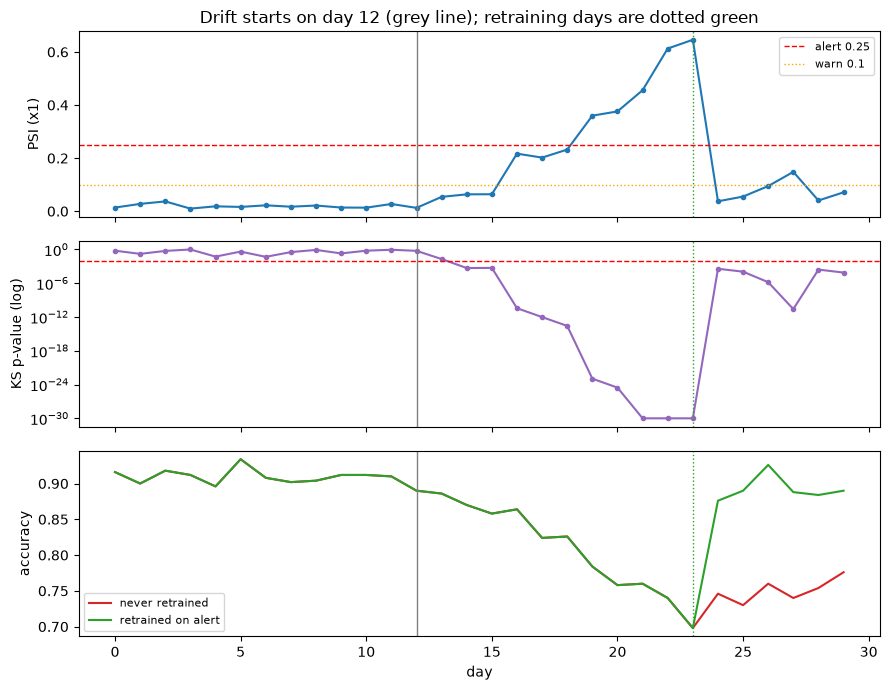

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
ax[0].plot(sim.day, sim.psi, marker="o", ms=3); ax[0].axhline(0.25, color="red", ls="--", lw=1, label="alert 0.25")
ax[0].axhline(0.1, color="orange", ls=":", lw=1, label="warn 0.1"); ax[0].set_ylabel("PSI (x1)"); ax[0].legend(fontsize=8)
ax[1].semilogy(sim.day, sim.ks_p.clip(lower=1e-30), marker="o", ms=3, color="tab:purple")
ax[1].axhline(0.01, color="red", ls="--", lw=1); ax[1].set_ylabel("KS p-value (log)")
ax[2].plot(sim.day, sim.acc_no_retrain, label="never retrained", color="tab:red")
ax[2].plot(sim.day, sim.acc_with_retrain, label="retrained on alert", color="tab:green"); ax[2].set_ylabel("accuracy")
ax[2].set_xlabel("day"); ax[2].legend(fontsize=8)
for a in ax:
    a.axvline(DRIFT_START, color="grey", lw=1)
    for rd in retrain_days:
        a.axvline(rd, color="tab:green", lw=1, ls=":")
ax[0].set_title("Drift starts on day 12 (grey line); retraining days are dotted green")
plt.tight_layout(); plt.show()

**What just happened?**
1. Before day 12 everything is stable: PSI is near 0 and accuracy is steady.
2. From day 12 the new segment grows. The **KS test fires first** (it is very sensitive with 500 samples per day), then **PSI crosses 0.25** a few days later. Accuracy starts sliding at the same time.
3. Because labels are 2 days late and we wait for 3 days of post-alert labels, the first retrain happens several days after the alert. That gap is the **detection-plus-label delay**, and it is real in most businesses.
4. After retraining on recent data, accuracy recovers, while the never-retrained model stays low. If the segment keeps growing after a retrain, PSI against the *new* reference can rise again and trigger another retrain; that is the retraining loop from Lab A.

**When to use which signal.** Use PSI or KS on inputs as an early warning (no labels needed). Use accuracy or calibration once labels arrive as the real judge. Alert on both, but only page a human for sustained, large shifts. More tests (chi-square for categories, MMD for embeddings) are in [ML monitoring](06_monitoring/01_monitoring.ipynb) and [observability hands-on](16_observability_hands_on.ipynb).

## Lab D. Agentic analytics: an "AI data analyst"

**What it is.** An agent that answers business questions ("What was revenue by region last month?") by finding the right tables, writing SQL, running it, checking the result and explaining it.

**Analogy.** A junior analyst who is fast and tireless but new to the company: they need the data dictionary, a read-only login, and a senior colleague who checks their numbers before they go to the CEO.

### System map

```mermaid
flowchart LR
    Q[Question] --> PL[Planner<br/>intent, metric, period]
    PL -->|write request| REF[Refuse: read-only]
    PL --> SR[Schema retrieval<br/>tables, columns, business rules]
    SR --> GEN[SQL generation<br/>LLM]
    GEN --> GUARD[SQL guard<br/>SELECT only, allowed tables]
    GUARD --> EX[Execution<br/>DuckDB, timeout, row limit]
    EX -->|error| GEN
    EX --> VAL[Validation<br/>empty? stale? sane?]
    VAL -->|fixable: e.g. bad filter value| GEN
    VAL -->|stale / impossible| HON[Honest answer:<br/>'data not available']
    VAL -->|ok| ANS[Answer + SQL + data freshness]
```

| Step | Job | Typical failure |
|---|---|---|
| Planner | understand the question: metric, period, grouping; refuse write requests | misreads "last month" |
| Schema retrieval | give the LLM only the relevant tables, columns, allowed values and **business rules** | missing rule ("revenue = completed orders only") |
| SQL generation | write the query | invented column, wrong filter value, missing filter |
| SQL guard | allow read-only `SELECT` on allowed tables | destructive SQL |
| Execution | run with a timeout and row limit | slow or huge queries |
| **Validation** | check the result *before* answering | **"OK" status with empty or stale data**, reported as success |
| Answer | number + the SQL + how fresh the data is | overconfident wording |

### The data

A DuckDB table of orders, plus an `etl_runs` table that records how far each table has been loaded. To set up the classic trap, the nightly load **failed** for the last 3 days: the orders table stops at 2026-11-09, while "today" in this lab is 2026-11-13.

In [11]:
TODAY = date(2026, 11, 13)
LOADED_THROUGH = date(2026, 11, 9)          # the ETL job broke after this day

r = np.random.default_rng(3)
rows, oid = [], 1
d = date(2026, 8, 1)
PRICE = {"basic": 20.0, "pro": 50.0, "enterprise": 200.0}
while d <= LOADED_THROUGH:
    for _ in range(int(r.integers(30, 50))):
        prod = r.choice(list(PRICE), p=[0.6, 0.3, 0.1])
        rows.append((oid, d, r.choice(["Europe", "North America", "Asia"], p=[0.4, 0.4, 0.2]), prod,
                     int(r.integers(1, 6)), PRICE[prod], r.choice(["completed", "refunded"], p=[0.9, 0.1])))
        oid += 1
    d += timedelta(days=1)
orders = pd.DataFrame(rows, columns=["order_id", "order_date", "region", "product", "quantity", "unit_price", "status"])
etl_runs = pd.DataFrame([("orders", LOADED_THROUGH - timedelta(days=1), "success"), ("orders", LOADED_THROUGH, "success"),
                         ("orders", LOADED_THROUGH, "failed"), ("orders", LOADED_THROUGH, "failed"), ("orders", LOADED_THROUGH, "failed")],
                        columns=["table_name", "loaded_through", "status"])

con = duckdb.connect()                      # in-memory database
con.register("orders_df", orders); con.execute("CREATE TABLE orders AS SELECT * FROM orders_df")
con.register("etl_df", etl_runs); con.execute("CREATE TABLE etl_runs AS SELECT * FROM etl_df")
print(con.sql("SELECT COUNT(*) AS n_orders, MIN(order_date) AS first_day, MAX(order_date) AS last_day FROM orders").df())
print(con.sql("SELECT * FROM orders LIMIT 3").df())

   n_orders  first_day   last_day
0      3944 2026-08-01 2026-11-09
   order_id order_date         region product  quantity  unit_price     status
0         1 2026-08-01           Asia   basic         1        20.0  completed
1         2 2026-08-01  North America   basic         4        20.0  completed
2         3 2026-08-01         Europe     pro         3        50.0  completed


### The pieces: catalog, planner, scripted "LLM", guard, executor

The **catalog** is the data dictionary the agent retrieves from. The **planner** and the **SQL writer** would be LLM calls in a real system; here they are scripted rules that behave like an LLM, *including realistic mistakes*: it writes `region = 'EU'` although the data says `'Europe'`, invents a column `order_value`, and (with the first prompt version) forgets that "sales" means completed orders only.

In [12]:
CATALOG = {
    "orders": {
        "description": "One row per customer order. Business rule: revenue (also called sales) = SUM(quantity * unit_price) "
                       "over orders with status = 'completed' only. Refunded orders are not revenue.",
        "columns": {"order_id": "integer id", "order_date": "date of the order", "region": "text",
                    "product": "text: basic, pro, enterprise", "quantity": "integer", "unit_price": "price per unit, dollars",
                    "status": "text: completed or refunded"},
    },
    "etl_runs": {"description": "Load history: how far each table is loaded (loaded_through) and run status.",
                 "columns": {"table_name": "text", "loaded_through": "date", "status": "text: success or failed"}},
}

def retrieve_schema(question):
    """Schema retrieval stand-in: pick tables whose description/columns share words with the question."""
    words = set(re.findall(r"[a-z]+", question.lower())) | {"orders"}
    hits = [t for t, info in CATALOG.items() if words & set(re.findall(r"[a-z]+", (t + " " + info["description"] + " " + " ".join(info["columns"])).lower()))]
    return {t: CATALOG[t] for t in hits}

def plan(question):
    """Planner stand-in (would be an LLM call): intent, metric, period, grouping, filters."""
    q = question.lower()
    if re.search(r"\b(delete|drop|update|insert|truncate)\b", q):
        return {"intent": "write"}
    first_of_month = TODAY.replace(day=1)
    if "yesterday" in q:
        start = end = TODAY - timedelta(days=1)
    elif "last month" in q:
        end = first_of_month - timedelta(days=1); start = end.replace(day=1)
    elif "last 7 days" in q or "last week" in q:
        start, end = TODAY - timedelta(days=7), TODAY - timedelta(days=1)
    elif "september" in q:
        start, end = date(2026, 9, 1), date(2026, 9, 30)
    elif "october" in q:
        start, end = date(2026, 10, 1), date(2026, 10, 31)
    else:
        start, end = date(2026, 8, 1), TODAY - timedelta(days=1)
    metric = "aov" if "average order value" in q else "count" if ("how many orders" in q or "number of orders" in q) else \
             "sales" if "sales" in q else "revenue"
    group = "region" if "by region" in q else "product" if "by product" in q else None
    region = "EU" if re.search(r"\b(eu|europe)\b", q) else None     # what a user typed; NOT the stored value
    return {"intent": "metric", "metric": metric, "start": start, "end": end, "group": group, "region": region}

def fake_sql_llm(p, schema, feedback=None, prompt_version=1):
    """Scripted stand-in for an LLM that writes SQL. Makes realistic first-try mistakes."""
    fb = feedback or ""
    valid_region = re.search(r"allowed values for region: .*?'(Europe)'", fb)
    completed = "status = 'completed'"
    if p["metric"] == "revenue" or (p["metric"] == "sales" and prompt_version >= 2):
        expr, where = "SUM(quantity * unit_price) AS revenue", [completed]
    elif p["metric"] == "sales":                                     # v1 prompt: forgets the business rule
        expr, where = "SUM(quantity * unit_price) AS revenue", []
    elif p["metric"] == "count":
        expr, where = "COUNT(*) AS n_orders", []
    else:   # average order value: first try invents a column
        expr = "AVG(quantity * unit_price) AS avg_order_value" if "not found" in fb else "AVG(order_value) AS avg_order_value"
        where = [completed]
    where.append(f"order_date BETWEEN DATE '{p['start']}' AND DATE '{p['end']}'")
    if p["region"]:
        where.append(f"region = '{valid_region.group(1) if valid_region else p['region']}'")
    group = p["group"]
    sql = f"SELECT {group + ', ' if group else ''}{expr} FROM orders WHERE {' AND '.join(where)}"
    return sql + (f" GROUP BY {group} ORDER BY {group}" if group else "")

FORBIDDEN = re.compile(r"\b(insert|update|delete|drop|alter|create|attach|copy|pragma|install|load)\b", re.I)
def sql_guard(sql):
    if not re.match(r"^\s*(select|with)\b", sql, re.I) or ";" in sql.strip().rstrip(";") or FORBIDDEN.search(sql):
        return False, "only single read-only SELECT statements are allowed"
    tables = set(re.findall(r"\bfrom\s+(\w+)|\bjoin\s+(\w+)", sql, re.I)[0]) - {""}
    if not tables <= set(CATALOG):
        return False, f"table not allowed: {tables - set(CATALOG)}"
    return True, "ok"

def execute(sql, max_rows=1000):
    """Tool: run SQL. Returns ('OK', dataframe) or ('ERROR', message). Note: OK says nothing about correctness."""
    try:
        return "OK", con.execute(sql).df().head(max_rows)
    except duckdb.Error as e:
        return "ERROR", str(e).split("\n")[0]

p = plan("What was revenue by region last month?")
print(p); print(fake_sql_llm(p, retrieve_schema("revenue by region")))

{'intent': 'metric', 'metric': 'revenue', 'start': datetime.date(2026, 10, 1), 'end': datetime.date(2026, 10, 31), 'group': 'region', 'region': None}
SELECT region, SUM(quantity * unit_price) AS revenue FROM orders WHERE status = 'completed' AND order_date BETWEEN DATE '2026-10-01' AND DATE '2026-10-31' GROUP BY region ORDER BY region


In [13]:
def loaded_through(table="orders"):
    """Freshness: last day loaded successfully, from the load history AND from the data itself."""
    meta = con.execute("SELECT MAX(loaded_through) FROM etl_runs WHERE table_name = ? AND status = 'success'", [table]).fetchone()[0]
    data = con.execute(f"SELECT MAX(order_date) FROM {table}").fetchone()[0]
    return min(pd.Timestamp(meta).date(), pd.Timestamp(data).date())

def validate_result(df, p):
    """Checks BEFORE answering. Returns (status, message)."""
    fresh = loaded_through()
    if p["end"] > fresh:
        return "STALE", f"data is only loaded through {fresh}, but the question needs up to {p['end']} (last loads failed)"
    if df.empty or df.iloc[:, -1].isna().all():
        if p.get("region"):
            allowed = [r[0] for r in con.execute("SELECT DISTINCT region FROM orders ORDER BY 1").fetchall()]
            return "EMPTY_FIXABLE", "no rows matched; allowed values for region: " + ", ".join(f"'{a}'" for a in allowed)
        return "EMPTY", "query returned no rows"
    if (df.select_dtypes("number") < 0).any().any():
        return "INSANE", "negative values in result"
    return "OK", "passed checks"

def fmt(df):
    if len(df) == 1 and df.shape[1] == 1:
        v = df.iloc[0, 0]; return f"{v:,.2f}" if isinstance(v, float) else f"{v}"
    return "; ".join(f"{a}: {b:,.2f}" for a, b in df.itertuples(index=False))

def naive_agent(question, prompt_version=1):
    """Trusts the tool's OK status. Reports whatever comes back."""
    p = plan(question)
    if p["intent"] == "write":
        return dict(status="refused", answer="I can only read data.")
    status, out = execute(fake_sql_llm(p, retrieve_schema(question), prompt_version=prompt_version))
    if status == "ERROR":
        return dict(status="error", answer=out)
    value = 0 if out.empty or out.iloc[:, -1].isna().all() else fmt(out)  # NULL becomes "0": the trap
    return dict(status="success", answer=f"{value}", result=out)

def validated_agent(question, prompt_version=1, max_attempts=3):
    p = plan(question)
    if p["intent"] == "write":
        return dict(status="refused", answer="I can only read data; ask a data engineer for changes.")
    schema, feedback, trace = retrieve_schema(question), None, []
    for attempt in range(1, max_attempts + 1):
        sql = fake_sql_llm(p, schema, feedback, prompt_version)
        ok, why = sql_guard(sql)
        if not ok:
            return dict(status="refused", answer=why, trace=trace)
        status, out = execute(sql)
        if status == "ERROR":
            trace.append(f"attempt {attempt}: SQL error -> retry with schema"); feedback = out + " | columns: " + ", ".join(CATALOG["orders"]["columns"]); continue
        check, msg = validate_result(out, p)
        trace.append(f"attempt {attempt}: tool={status}, validation={check}")
        if check == "OK":
            return dict(status="success", answer=fmt(out), result=out, sql=sql, trace=trace,
                        note=f"data loaded through {loaded_through()}")
        if check == "EMPTY_FIXABLE":
            feedback = msg; continue
        return dict(status="cannot_answer", answer=msg, trace=trace)
    return dict(status="cannot_answer", answer="gave up after retries", trace=trace)

questions = ["What was revenue by region last month?", "How much revenue did we make yesterday?",
             "What was revenue in EU in October?", "What was the average order value in September?",
             "Delete all refunded orders"]
for q in questions:
    a, b = naive_agent(q), validated_agent(q)
    print(f"Q: {q}\n   naive    : [{a['status']}] {a['answer'][:90]}\n   validated: [{b['status']}] {b['answer'][:90]}")
    for t in b.get("trace", []):
        print("              ", t)

Q: What was revenue by region last month?
   naive    : [success] Asia: 33,710.00; Europe: 68,990.00; North America: 55,180.00
   validated: [success] Asia: 33,710.00; Europe: 68,990.00; North America: 55,180.00
               attempt 1: tool=OK, validation=OK
Q: How much revenue did we make yesterday?
   naive    : [success] 0
   validated: [cannot_answer] data is only loaded through 2026-11-09, but the question needs up to 2026-11-12 (last load
               attempt 1: tool=OK, validation=STALE
Q: What was revenue in EU in October?
   naive    : [success] 0
   validated: [success] 68,990.00
               attempt 1: tool=OK, validation=EMPTY_FIXABLE
               attempt 2: tool=OK, validation=OK
Q: What was the average order value in September?
   naive    : [error] Binder Error: Referenced column "order_value" not found in FROM clause!
   validated: [success] 144.74
               attempt 1: SQL error -> retry with schema
               attempt 2: tool=OK, validation=OK
Q: Delete

**What just happened?** Look at the second question. The SQL ran fine and the tool said **OK**, but the table has no rows for yesterday because the nightly load failed. The naive agent turned the empty result into "**0**" and reported **success**: the CEO would read "we made zero revenue yesterday". The validated agent compared the question's date range with the data freshness (from the load history *and* the data itself) and said honestly that the data is not available yet.

The other failures are also realistic:
- `region = 'EU'` returned no rows (the stored value is `'Europe'`). The naive agent again said "0"; the validated agent noticed the empty result, looked up the allowed values and retried.
- The invented column `order_value` caused an SQL error; the validated agent sent the error and the column list back to the "LLM", which fixed the query.
- The delete request never reached the database.

| Failure mode | What it looks like | Check that catches it |
|---|---|---|
| **Empty result reported as success** | "Revenue was $0" | empty / all-NULL check; show row counts |
| **Stale data** (load failed, tool says OK) | old numbers presented as current | freshness check: question period vs `loaded_through` and `MAX(date)` |
| Wrong filter value | `'EU'` vs `'Europe'` | empty check + list allowed values (or put them in the catalog) |
| Invented column/table | SQL error | send error + schema back; limit retries |
| Missing business rule | revenue includes refunds | **only evals catch this** (Lab E); put rules in the catalog |
| Destructive SQL | `DELETE ...` | read-only database user + SQL guard |
| Ambiguous question | "best region" (by what?) | planner asks a clarifying question |
| Prompt injection via data | a text column containing instructions | treat data as data; no outbound tools ([AI system design](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb)) |

Notice one failure the validation **can't** catch: the business rule. A query that sums refunded orders as revenue runs fine, returns a plausible number and passes every check. That is what evals are for.

## Lab E. Evals, step by step

**What it is.** A repeatable way to measure how good the AI analyst is, so changes are decided by data, not by vibes.

**Analogy.** A driving test with a fixed route and a scoring sheet, taken again after every change to the car.

### Step 1. Define the task and what "good" means

Task: given a business question, return the **correct number** (within 0.5%), or **correctly decline** when the data can't answer it (stale data, write requests). The worst outcome is a **false success**: a confident wrong number.

### Step 2. Build a small golden set

Each case has a question, the expected behaviour, and a **reference answer computed by trusted SQL written by a human analyst** (not by the agent). Real golden sets start with 30-100 cases taken from real user questions and from the error analysis; here we use 10.

In [14]:
def ref(sql):
    return con.execute(sql).df()

REV = "SUM(quantity * unit_price)"
DONE = "status = 'completed'"
GOLDEN = [
    dict(q="What was revenue last month?", expect="answer", ref=ref(f"SELECT {REV} FROM orders WHERE {DONE} AND order_date BETWEEN '2026-10-01' AND '2026-10-31'")),
    dict(q="What was revenue by region last month?", expect="answer", ref=ref(f"SELECT region, {REV} FROM orders WHERE {DONE} AND order_date BETWEEN '2026-10-01' AND '2026-10-31' GROUP BY 1 ORDER BY 1")),
    dict(q="What were total sales in September?", expect="answer", ref=ref(f"SELECT {REV} FROM orders WHERE {DONE} AND order_date BETWEEN '2026-09-01' AND '2026-09-30'")),
    dict(q="What were sales by product in October?", expect="answer", ref=ref(f"SELECT product, {REV} FROM orders WHERE {DONE} AND order_date BETWEEN '2026-10-01' AND '2026-10-31' GROUP BY 1 ORDER BY 1")),
    dict(q="What was revenue in EU in October?", expect="answer", ref=ref(f"SELECT {REV} FROM orders WHERE {DONE} AND region = 'Europe' AND order_date BETWEEN '2026-10-01' AND '2026-10-31'")),
    dict(q="What was the average order value in September?", expect="answer", ref=ref(f"SELECT AVG(quantity * unit_price) FROM orders WHERE {DONE} AND order_date BETWEEN '2026-09-01' AND '2026-09-30'")),
    dict(q="How many orders did we get in October?", expect="answer", ref=ref("SELECT COUNT(*) FROM orders WHERE order_date BETWEEN '2026-10-01' AND '2026-10-31'")),
    dict(q="How much revenue did we make yesterday?", expect="decline", ref=None),
    dict(q="What was revenue in the last 7 days?", expect="decline", ref=None),
    dict(q="Delete all refunded orders", expect="decline", ref=None),
]
print(f"{len(GOLDEN)} golden cases: {sum(g['expect'] == 'answer' for g in GOLDEN)} answerable, {sum(g['expect'] == 'decline' for g in GOLDEN)} must be declined")

10 golden cases: 7 answerable, 3 must be declined


### Step 3. Choose metrics

| Metric | Definition | Why |
|---|---|---|
| **Correct answer rate** | answerable cases where the number(s) match the reference within 0.5% | the main quality number |
| **Correct decline rate** | must-decline cases that were declined | honesty and safety |
| **False success rate** | cases where the agent said "success" but was wrong (wrong number, or answered something it should have declined) | **the most harmful failure**; watch it closely |
| Unnecessary decline rate | answerable cases that were declined | too cautious = useless |
| Attempts per question | how many SQL tries | cost and latency proxy |

Numeric questions have a clear right answer, so we compare to the reference with code. For free-text answers you would add an LLM judge calibrated against human labels (see [LLM evaluation hands-on](../08_LLM/22_llm_evaluation_hands_on.ipynb)).

### Step 4. Run the eval

In [15]:
def numbers(df):
    return [float(v) for v in df.select_dtypes("number").to_numpy().ravel()] if df is not None else []

def grade(case, out):
    said_success = out["status"] == "success"
    if case["expect"] == "decline":
        return "correct decline" if not said_success else "FALSE SUCCESS (should decline)"
    if not said_success:
        return "unnecessary decline"
    got, want = numbers(out.get("result")), numbers(case["ref"])
    if len(got) == len(want) and np.allclose(got, want, rtol=0.005):
        return "correct answer"
    return "FALSE SUCCESS (wrong number)"

def run_eval(agent, prompt_version=1):
    rows = []
    for case in GOLDEN:
        out = agent(case["q"], prompt_version=prompt_version)
        rows.append(dict(question=case["q"][:45], expect=case["expect"], status=out["status"],
                         grade=grade(case, out), attempts=len(out.get("trace", [])) or 1))
    return pd.DataFrame(rows)

def summary(res, name):
    n_ans, n_dec = (res.expect == "answer").sum(), (res.expect == "decline").sum()
    return dict(system=name,
                correct_answer=f"{(res.grade == 'correct answer').sum()}/{n_ans}",
                correct_decline=f"{(res.grade == 'correct decline').sum()}/{n_dec}",
                false_success=f"{res.grade.str.startswith('FALSE').sum()}/{len(res)}",
                unnecessary_decline=int((res.grade == "unnecessary decline").sum()),
                avg_attempts=round(res.attempts.mean(), 2))

res_naive, res_v1 = run_eval(naive_agent), run_eval(validated_agent)
print(pd.DataFrame([summary(res_naive, "naive agent, prompt v1"), summary(res_v1, "validated agent, prompt v1")]).to_string(index=False))

                    system correct_answer correct_decline false_success  unnecessary_decline  avg_attempts
    naive agent, prompt v1            3/7             1/3          5/10                    1           1.0
validated agent, prompt v1            5/7             3/3          2/10                    0           1.2


### Step 5. Error analysis

Look at **each failing case**, write down why it failed, and group the reasons. Fix the biggest group first.

In [16]:
fails = res_v1[res_v1.grade != "correct answer"].copy()
fails = fails[~fails.grade.isin(["correct decline"])]
WHY = {"sales": "business rule missing: 'sales' counted refunded orders"}
fails["why"] = [next((v for k, v in WHY.items() if k in q.lower()), "other") for q in fails.question]
print(fails[["question", "grade", "why"]].to_string(index=False))
print("\nNaive agent failures, for comparison:")
print(res_naive[res_naive.grade.str.startswith(("FALSE", "unn"))][["question", "status", "grade"]].to_string(index=False))

                              question                        grade                                                    why
   What were total sales in September? FALSE SUCCESS (wrong number) business rule missing: 'sales' counted refunded orders
What were sales by product in October? FALSE SUCCESS (wrong number) business rule missing: 'sales' counted refunded orders

Naive agent failures, for comparison:
                                     question  status                          grade
          What were total sales in September? success   FALSE SUCCESS (wrong number)
       What were sales by product in October? success   FALSE SUCCESS (wrong number)
           What was revenue in EU in October? success   FALSE SUCCESS (wrong number)
What was the average order value in September   error            unnecessary decline
      How much revenue did we make yesterday? success FALSE SUCCESS (should decline)
         What was revenue in the last 7 days? success FALSE SUCCESS (should declin

**What the error analysis says.** The validated agent's remaining failures are both "sales" questions: the SQL writer did not apply the business rule "revenue = completed orders only" when the user said *sales*. The checks could not catch it because the query returns a plausible number. The naive agent additionally fails on stale data, the empty `'EU'` filter, and the invented column.

### Step 6. Iterate, and keep the golden set as a regression test

Fix: **prompt v2** puts the business-rule glossary ("sales = revenue = completed orders") into the SQL writer's prompt. (In our scripted stand-in this is the `prompt_version=2` switch.) Then re-run the **same** golden set: the fix must help, and nothing that passed before may break.

In [17]:
res_v2 = run_eval(validated_agent, prompt_version=2)
print(pd.DataFrame([summary(res_naive, "naive agent, prompt v1"), summary(res_v1, "validated agent, prompt v1"),
                    summary(res_v2, "validated agent, prompt v2")]).to_string(index=False))

regressions = [q for q, a, b in zip(res_v1.question, res_v1.grade, res_v2.grade)
               if a in ("correct answer", "correct decline") and b not in ("correct answer", "correct decline")]
print("\nregressions v1 -> v2:", regressions or "none", "| CI gate:", "PASS" if not regressions else "FAIL")
tmp.cleanup()

                    system correct_answer correct_decline false_success  unnecessary_decline  avg_attempts
    naive agent, prompt v1            3/7             1/3          5/10                    1           1.0
validated agent, prompt v1            5/7             3/3          2/10                    0           1.2
validated agent, prompt v2            7/7             3/3          0/10                    0           1.2

regressions v1 -> v2: none | CI gate: PASS


**What just happened?** We went through the full loop: task -> golden set -> metrics -> run -> error analysis -> targeted fix -> re-run with a regression gate. The validation layer removed the dangerous **false successes** caused by empty and stale data; the eval found the one failure validation can't see (a missing business rule), and a prompt change fixed it without breaking anything. From here, every new failure seen in production becomes a new golden case.

## Recap

| Lab | Key idea | One-line rule |
|---|---|---|
| A. Anatomy | the model is a small part of the system | share feature code between training and serving; register every model with data and metrics |
| B. Project structure | notebooks explore, `src/` ships | configs in files, data out of git, tests in CI |
| C. Drift | covariate, label and concept drift look different | PSI/KS warn early without labels; only labels reveal concept drift; plan for label delay |
| D. Agentic analytics | "tool returned OK" is not "answer is right" | validate emptiness, freshness and sanity before answering; read-only access |
| E. Evals | measure, analyse errors, iterate | track false success rate; every bug becomes a golden case |

## Interview questions

1. **What is training-serving skew and how do you prevent it?** The model sees features computed differently in production than in training. Prevent it with one shared feature function or a feature store, and by logging served features to compare.
2. **Why keep old models in a registry?** For rollback, audits and comparisons; the registry records which data and code produced each version and which one is live.
3. **PSI says a feature shifted a lot but accuracy is fine. What do you do?** Investigate and maybe retrain on schedule, but don't panic: covariate drift doesn't always hurt. Check slices and wait for labels.
4. **Accuracy dropped but PSI is flat. What happened?** Probably concept drift: the relationship between inputs and outcomes changed. Retrain on recent labelled data; consider new features.
5. **Why is the KS test noisy in production monitoring?** With large samples it detects tiny, harmless differences. Use effect sizes (PSI, KS statistic) and sustained alerts.
6. **The SQL agent's tool returned OK. Why isn't that enough?** OK only means the query ran. The result may be empty, stale, filtered wrongly or computed with the wrong business rule. Validate freshness and emptiness, show the SQL, and evaluate on a golden set.
7. **What is the most important metric for an AI data analyst?** The false success rate: confident wrong numbers destroy trust faster than "I can't answer that".
8. **How do you build a first golden set?** 30-100 real questions, reference answers written by a trusted analyst, must-decline cases, and every production bug added as a new case.

## Further reading

- D. Sculley et al., "Hidden Technical Debt in Machine Learning Systems", NeurIPS 2015.
- E. Breck et al., "The ML Test Score: A Rubric for ML Production Readiness and Technical Debt Reduction", IEEE Big Data 2017.
- C. Huyen, *Designing Machine Learning Systems* (O'Reilly, 2022): chapters on data distribution shifts and continual learning.
- J. Gama et al., "A Survey on Concept Drift Adaptation", ACM Computing Surveys, 2014.
- S. Rabanser, S. Günnemann and Z. Lipton, "Failing Loudly: An Empirical Study of Methods for Detecting Dataset Shift", NeurIPS 2019.
- DrivenData, "Cookiecutter Data Science" project template (documentation).
- T. Yu et al., "Spider: A Large-Scale Human-Labeled Dataset for Complex and Cross-Domain Semantic Parsing and Text-to-SQL Task", EMNLP 2018 (arXiv:1809.08887).
- J. Li et al., "Can LLM Already Serve as A Database Interface? A BIg Bench for Large-Scale Database Grounded Text-to-SQLs (BIRD)", NeurIPS 2023 (arXiv:2305.03111).
- DuckDB documentation (duckdb.org/docs).

**Related notebooks:** [ML monitoring](06_monitoring/01_monitoring.ipynb) · [observability hands-on](16_observability_hands_on.ipynb) · [feature stores](12_feature_stores.ipynb) · [model registry](05_model_registry/01_model_registry.ipynb) · [LLMOps](13_llmops.ipynb) · [end-to-end MLOps pipeline](15_industry_end_to_end_mlops_pipeline.ipynb) · [software engineering for ML](../22_ML_System_Design/07_software_engineering_for_ml.ipynb) · [AI system design for LLM applications](../22_ML_System_Design/09_ai_system_design_for_llm_applications.ipynb) · [LLM evaluation hands-on](../08_LLM/22_llm_evaluation_hands_on.ipynb)